In [11]:
import pandas as pd
import numpy as np
from pathlib import Path

In [12]:
!python smaparsing.py


sp500 1950-01-03 2026-10-09 19315 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 7.0
nasdaq_comp 1971-02-05 2026-10-09 14037 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 7.0
nasdaq100 1985-10-01 2026-10-09 10336 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 7.0
ftse100 1984-01-03 2026-10-09 10805 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 5.0
nikkei 1965-01-05 2026-10-09 15183 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 11.0
dax 1987-12-30 2026-10-09 9807 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 6.0
cac40 1990-03-01 2026-10-09 9299 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 6.0
hang_seng 1986-12-31 2026-10-09 9816 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 7.0
shanghai 1997-07-02 2026-10-09 7089 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 20.0


In [13]:
original_data_path = Path("/home/pedrosalgado22/Documents/Github Repositories/SMAstrategy/data/raw")

processed_data_path = Path("/home/pedrosalgado22/Documents/Github Repositories/SMAstrategy/data/processed")

In [14]:
PAYMENT = 1087 # a year has about 52.2 weeks but only 12 months so 250 per week == 1087 per month
INTEREST_RATE = 0.02
START_DATE = "1986-01-01"

DIV_YIELD = { 
    "sp500": 0.02, "nasdaq_comp": 0.01, "nasdaq100": 0.01, "ftse100": 0.04,
    "nikkei": 0.01, "dax": 0.0, "cac40": 0.03, "hang_seng": 0.03, "shanghai": 0.02,
}

STRATEGIES = {"DCA": None, "SMA50": "sma_50", "SMA100": "sma_100", "SMA200": "sma_200"}

In [15]:
import pandas as pd

def simulate(df, sma_col, dividend_yield, values=None):
    dates = df.index.tolist()
    closes = df["Close"].tolist()
    if sma_col is not None:
        smas = df[sma_col].tolist()

    valid = df[(df.index >= START_DATE) & df["sma_200"].notna()]  # first day with sma_200 available
    start = df.index.get_loc(valid.index[0])

    cash = 0
    units = 0
    units_bought = 0
    total_spent = 0
    total_invested = 0
    n_buys = 0
    next_payment = dates[start].replace(day=1)  # payments on the 1st of each month
    if next_payment < dates[start]:
        next_payment += pd.DateOffset(months=1)

    for i in range(start, len(df)):
        days = (dates[i] - dates[i - 1]).days
        cash *= (1 + INTEREST_RATE) ** (days / 365)
        units *= (1 + dividend_yield) ** (days / 365)

        while next_payment <= dates[i]:
            cash += PAYMENT
            total_invested += PAYMENT
            next_payment += pd.DateOffset(months=1)

        if sma_col is None:
            signal = True
        else:
            signal = closes[i - 1] <= smas[i - 1]

        if cash > 0 and signal:
            units += cash / closes[i]
            units_bought += cash / closes[i]
            total_spent += cash
            n_buys += 1
            cash = 0

        if values is not None:
            values.append(units * closes[i] + cash)

    final_value = units * closes[-1] + cash
    return {
        "start_date": dates[start].date(),
        "end_date": dates[-1].date(),
        "total_invested": total_invested,
        "final_value": final_value,
        "total_return_pct": (final_value / total_invested - 1) * 100,
        "units": units,
        "avg_price": total_spent / units_bought if units_bought > 0 else None,
        "leftover_cash": cash,
        "n_buys": n_buys,
    }

In [16]:
df = pd.read_csv(processed_data_path / "sp500_processed.csv", index_col=0, parse_dates=True)
rows = []
for strategy, sma_col in STRATEGIES.items():
    rows.append(simulate(df, sma_col, DIV_YIELD["sp500"]))
pd.DataFrame(rows, index=STRATEGIES.keys())

,start_date,end_date,total_invested,final_value,total_return_pct,units,avg_price,leftover_cash,n_buys
DCA,1986-01-02,2026-10-09,531543,9.075036e+06,1607.300484,1161.747385,835.312961,0.000000,489
SMA50,1986-01-02,2026-10-09,531543,9.056210e+06,1603.758664,1159.198109,835.791791,1087.471893,320
SMA100,1986-01-02,2026-10-09,531543,8.995757e+06,1592.385639,1150.759714,833.781105,6551.817141,245
SMA200,1986-01-02,2026-10-09,531543,8.950325e+06,1583.838390,1144.943664,839.489717,6551.817141,176


In [17]:
results_path = processed_data_path.parent.parent / "results"
results_path.mkdir(exist_ok=True)

rows = []
for name in DIV_YIELD:
    df = pd.read_csv(processed_data_path / f"{name}_processed.csv", index_col=0, parse_dates=True)
    for strategy, sma_col in STRATEGIES.items():
        row = {"index": name, "strategy": strategy}
        row.update(simulate(df, sma_col, DIV_YIELD[name]))
        rows.append(row)

results = pd.DataFrame(rows)

results.to_csv(results_path / "results.csv", index=False)

display(
    results.style.format({
        "total_invested": "{:,.0f}",
        "final_value": "{:,.0f}",
        "total_return_pct": "{:,.2f}",
        "units": "{:,.2f}",
        "avg_price": "{:,.2f}",
        "leftover_cash": "{:,.2f}",
    }, na_rep="NaN")
)

,index,strategy,start_date,end_date,total_invested,final_value,total_return_pct,units,avg_price,leftover_cash,n_buys
0,sp500,DCA,1986-01-02,2026-10-09,"531,543","9,075,036","1,607.30","1,161.75",835.31,0.00,489
1,sp500,SMA50,1986-01-02,2026-10-09,"531,543","9,056,210","1,603.76","1,159.20",835.79,"1,087.47",320
2,sp500,SMA100,1986-01-02,2026-10-09,"531,543","8,995,757","1,592.39","1,150.76",833.78,"6,551.82",245
3,sp500,SMA200,1986-01-02,2026-10-09,"531,543","8,950,325","1,583.84","1,144.94",839.49,"6,551.82",176
4,nasdaq_comp,DCA,1986-01-02,2026-10-09,"531,543","14,867,339","2,697.02",543.27,"1,338.75",0.00,489
5,nasdaq_comp,SMA50,1986-01-02,2026-10-09,"531,543","14,751,606","2,675.24",539.01,"1,347.59","1,087.47",312
6,nasdaq_comp,SMA100,1986-01-02,2026-10-09,"531,543","14,732,461","2,671.64",538.31,"1,351.40","1,087.47",242
7,nasdaq_comp,SMA200,1986-01-02,2026-10-09,"531,543","14,782,445","2,681.04",539.93,"1,338.79","6,551.82",180
8,nasdaq100,DCA,1986-07-16,2026-10-09,"525,021","28,903,328","5,405.18",935.89,778.10,0.00,483
9,nasdaq100,SMA50,1986-07-16,2026-10-09,"525,021","28,663,377","5,359.47",928.09,783.84,"1,087.47",314


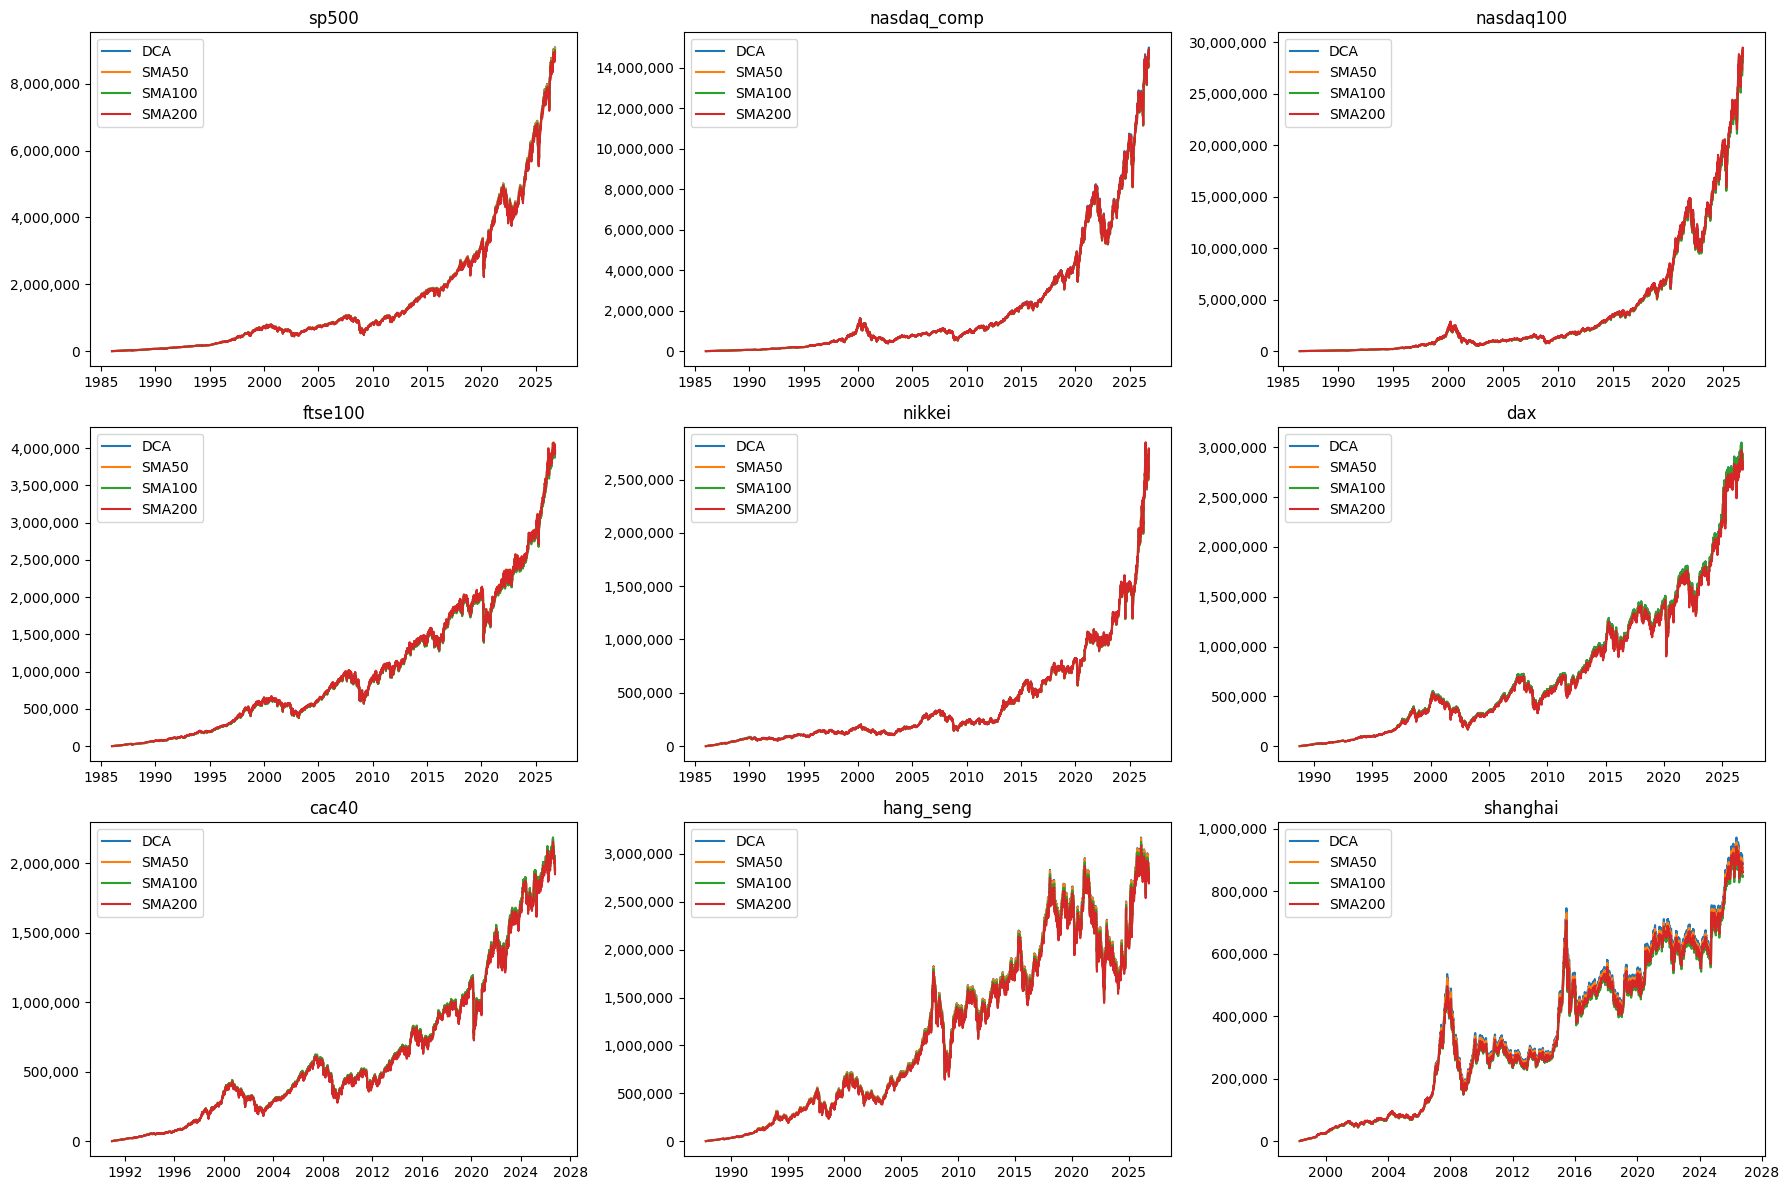

In [18]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

fig, axes = plt.subplots(3, 3, figsize=(18, 12))
for ax, name in zip(axes.flatten(), DIV_YIELD):
    df = pd.read_csv(processed_data_path / f"{name}_processed.csv", index_col=0, parse_dates=True).dropna(subset=["Close"])
    for strategy, sma_col in STRATEGIES.items():
        values = []
        simulate(df, sma_col, DIV_YIELD[name], values)
        ax.plot(df.index[-len(values):], values, label=strategy)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.set_title(name)
    ax.legend()
plt.tight_layout()
plt.show()

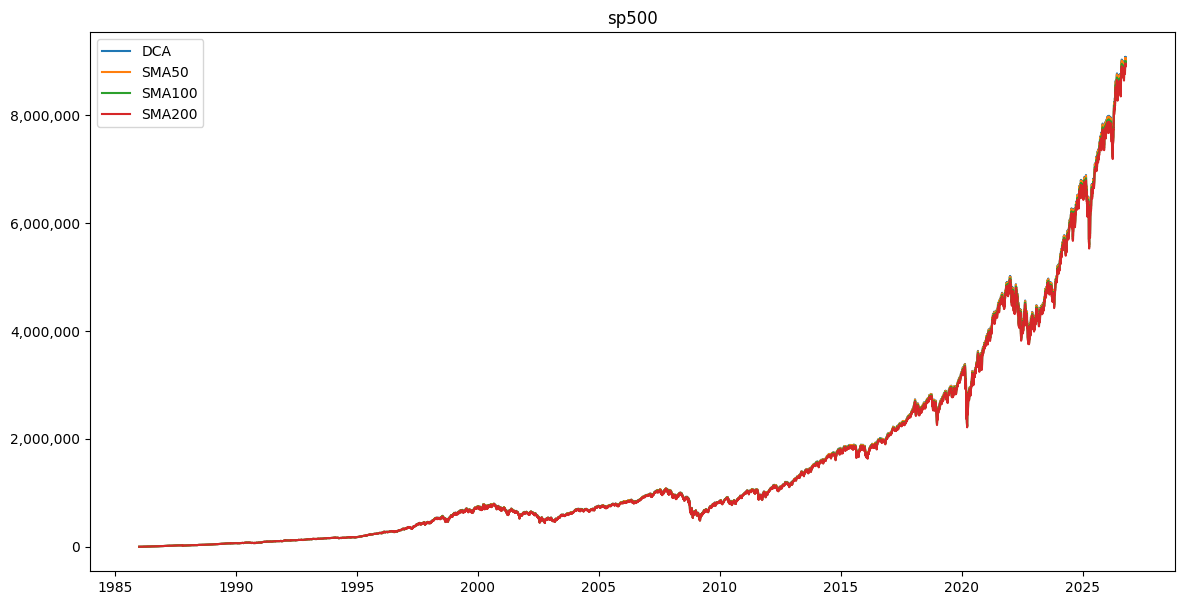

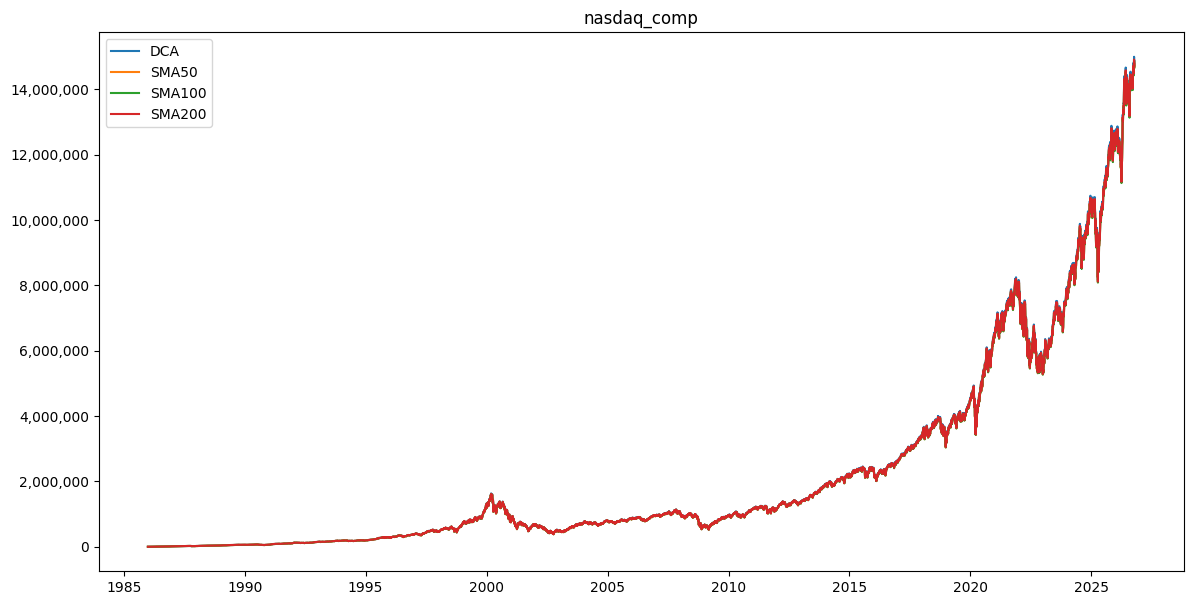

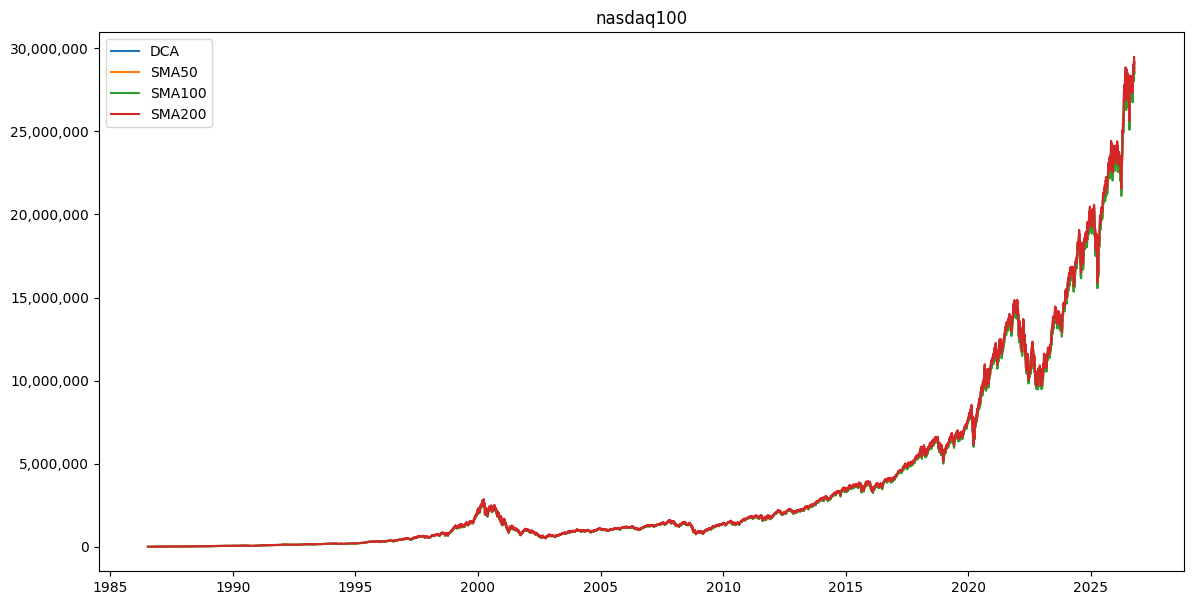

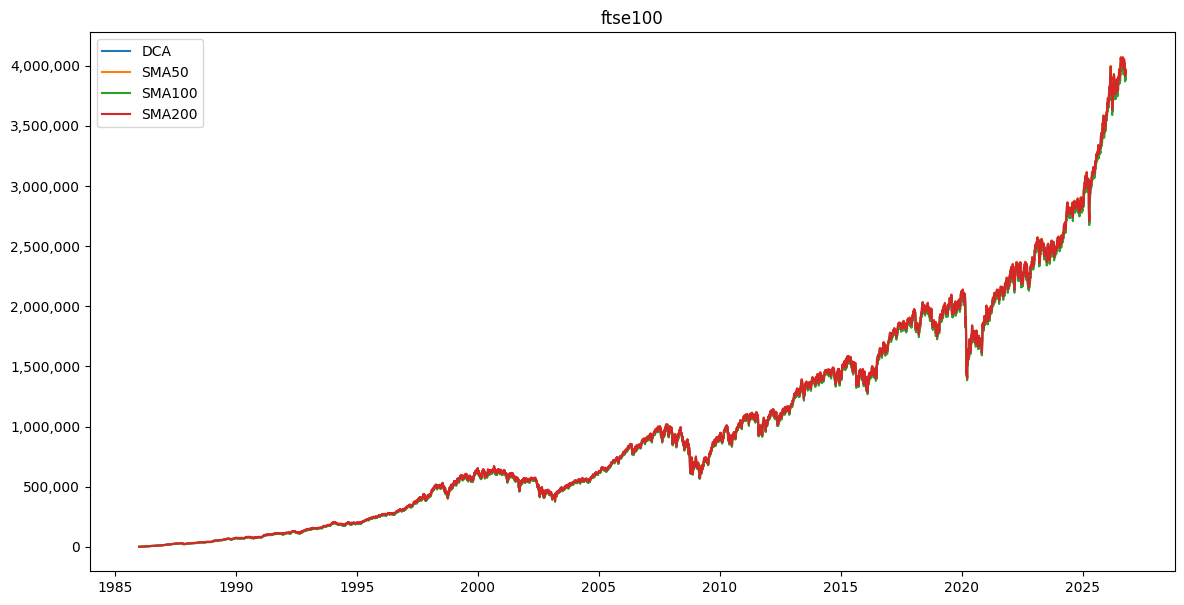

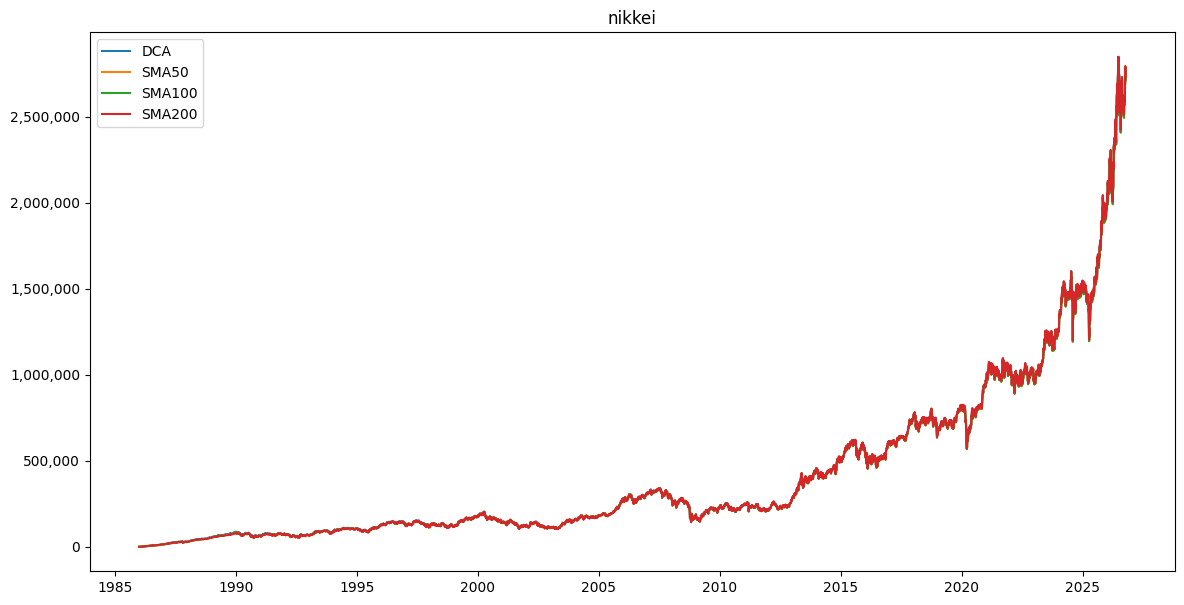

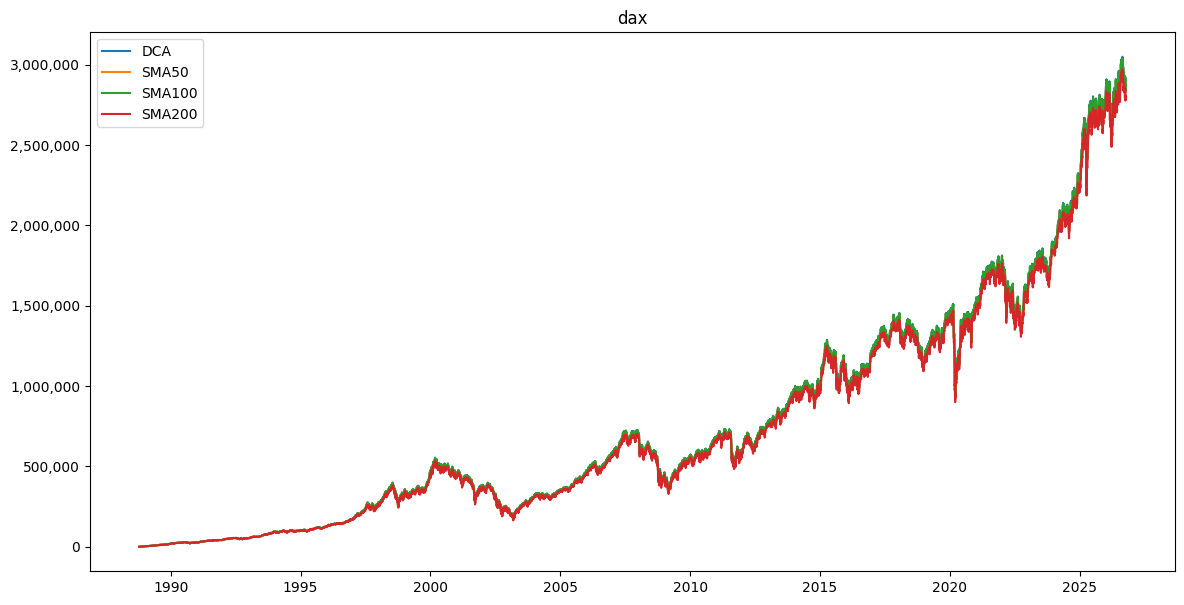

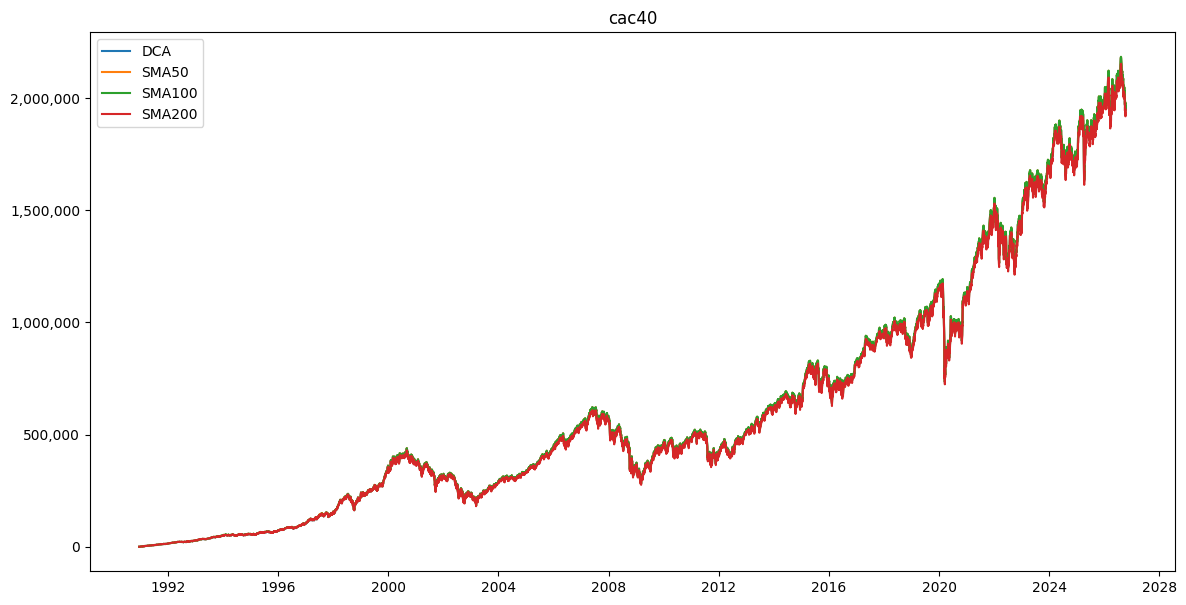

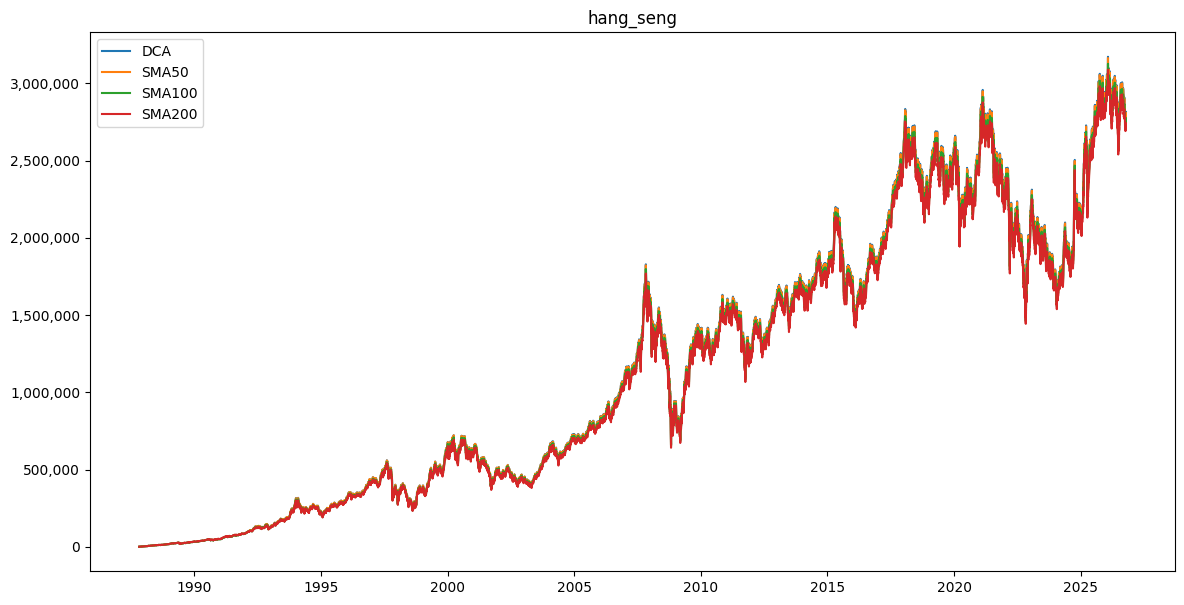

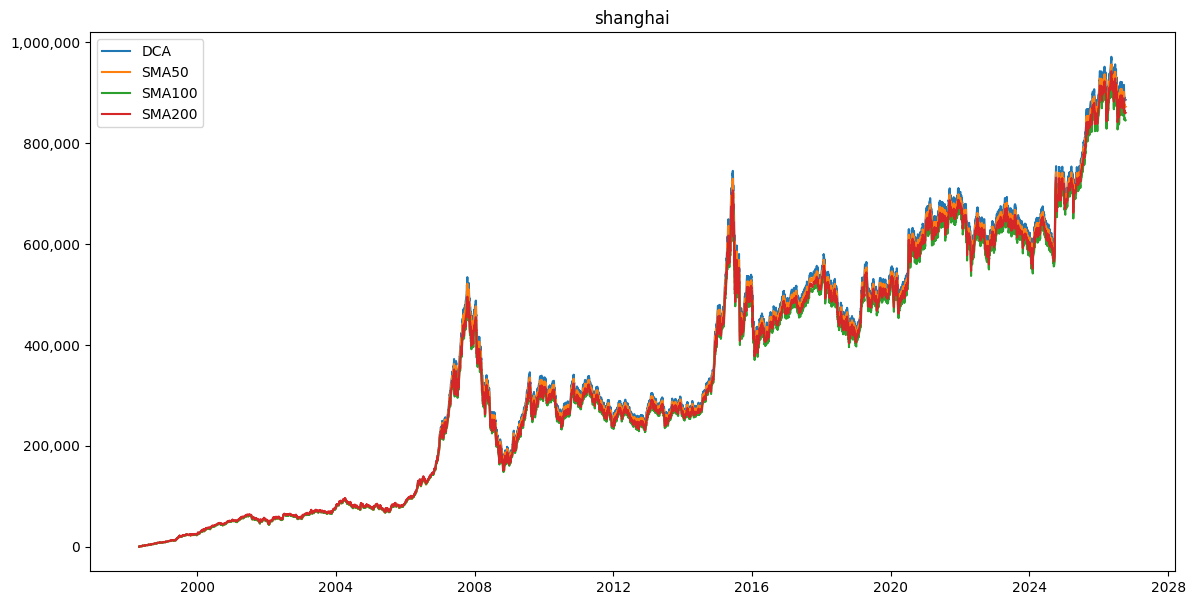

In [19]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

for name in DIV_YIELD:
    df = pd.read_csv(processed_data_path / f"{name}_processed.csv", index_col=0, parse_dates=True).dropna(subset=["Close"])
    fig, ax = plt.subplots(figsize=(14, 7))
    for strategy, sma_col in STRATEGIES.items():
        values = []
        simulate(df, sma_col, DIV_YIELD[name], values)
        series = pd.Series(values, index=df.index[-len(values):])["1986-01-01":]
        ax.plot(series.index, series.values, label=strategy)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.set_title(name)
    ax.legend()
    plt.show()

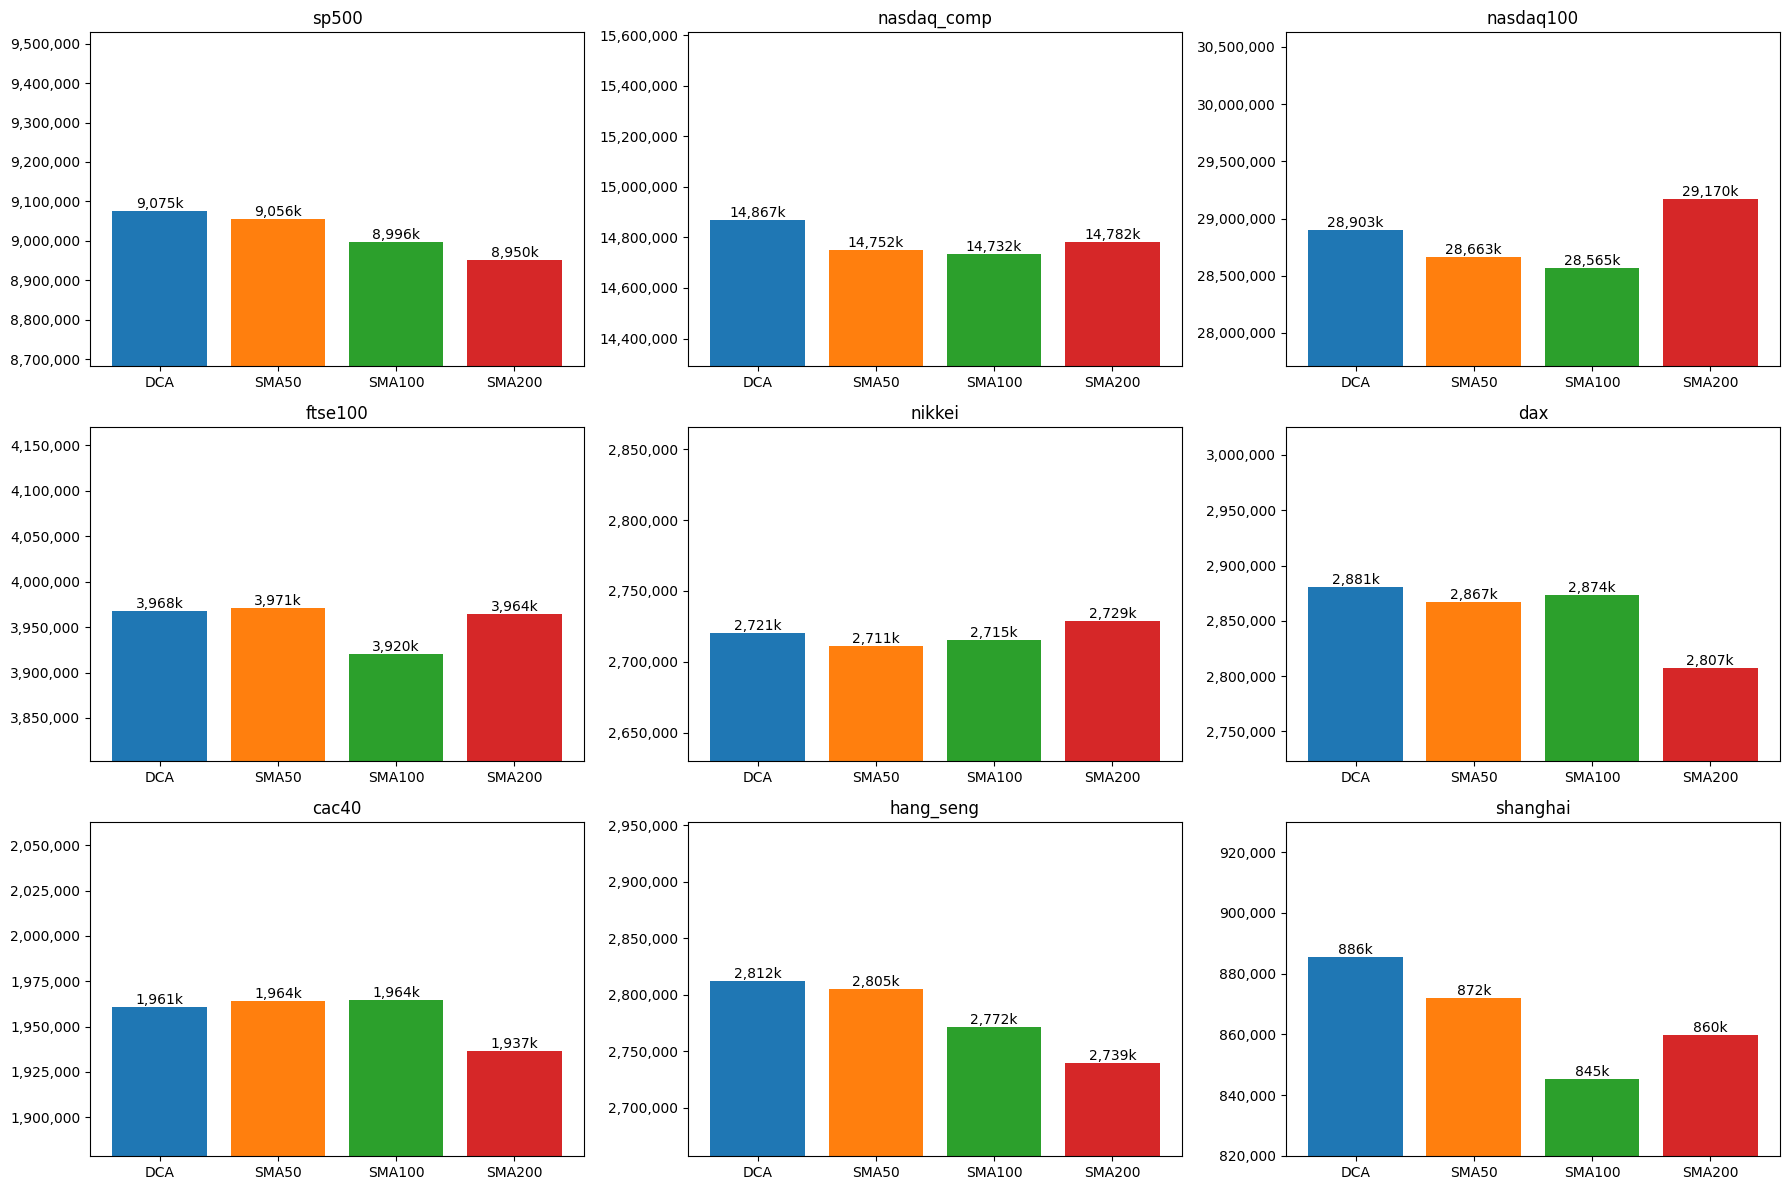

In [20]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]

fig, axes = plt.subplots(3, 3, figsize=(18, 12))
for ax, name in zip(axes.flatten(), DIV_YIELD):
    df = pd.read_csv(processed_data_path / f"{name}_processed.csv", index_col=0, parse_dates=True).dropna(subset=["Close"])
    final_values = []
    labels = []
    for strategy, sma_col in STRATEGIES.items():
        result = simulate(df, sma_col, DIV_YIELD[name])
        final_values.append(result["final_value"])
        labels.append(f"{result['final_value'] / 1000:,.0f}k")
    bars = ax.bar(list(STRATEGIES), final_values, color=colors)
    ax.bar_label(bars, labels=labels)
    ax.set_ylim(bottom=min(final_values) * 0.97)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.set_title(name)
plt.tight_layout()
plt.show()